# Lab: NumPy

**Meta:** importar NumPy (`import numpy as np`); poner mediciones en un **arreglo** (`np.array`); operar de forma **vectorizada** (sobre todos los elementos a la vez); calcular agregados (`np.mean`, `np.std`, `np.sum`, `np.max`, `np.min`); indexar y manejar una **matriz** 2D; y filtrar con una **máscara booleana**. Es el mismo dato de la L19, pero ahora calculas sobre todo el arreglo de golpe. En la segunda parte usarás las mismas herramientas sobre una **imagen a color** (un arreglo 3D): pintarás una bandera con **rebanadas**, cambiarás sus **canales** de color y la recolorearás con una **máscara**, y verás qué pasa cuando un color se pasa de 255. Acompaña a la nota de concepto [NumPy](l20_concept_numpy.qmd).

> **Cómo usar este lab:** ejecuta cada celda con `Shift + Enter`, empezando por las dos celdas de preparación. Donde diga **Predice**, piensa primero qué pasaría y después ejecuta la celda; la respuesta está en el bloque desplegable que le sigue (en el Paso 4 la línea daría un error a propósito, por eso está comentada con `#` -- déjala así). En **Tu turno**, los Ejercicios 1 y 2 traen un bloque comentado con una parte marcada con `____` que debes **completar** al quitar los `#`; el Ejercicio 3 (opcional) lo escribes tú desde cero. Compara con la respuesta esperada de cada bloque desplegable.

## Preparación

NumPy no es parte de Python estándar: hay que **instalarlo** (en Colab) e **importarlo**. También usaremos **matplotlib**, solo para *ver* las imágenes de los Pasos 5 a 7 (la estudiarás en la L23). Corre estas **dos** celdas primero. La primera instala NumPy y matplotlib (en Colab; si ya están, no hace nada). La segunda los importa y define `mostrar(imagen)`, una función ayudante que dibuja un arreglo como imagen: úsala tal cual, no es el tema de hoy.

In [1]:
%pip install -q numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt


def mostrar(imagen):
    # Ayudante: dibuja un arreglo como imagen (matplotlib llega en la L23).
    plt.figure(figsize=(4, 3))
    plt.imshow(imagen, interpolation="nearest")
    plt.xticks([])    # sin marcas en los ejes; el marco deja ver lo blanco
    plt.yticks([])
    plt.show()


print("NumPy y matplotlib listos para trabajar")

NumPy y matplotlib listos para trabajar


~~~text
NumPy y matplotlib listos para trabajar
~~~

## Paso 1: crear un arreglo

Un **arreglo** de NumPy se crea con `np.array(...)` a partir de una lista. Pongamos las temperaturas de la L19 en un arreglo:

In [3]:
temperaturas = np.array([18.0, 21.0, 17.0, 22.0, 19.0, 20.0])
print(temperaturas)
print(type(temperaturas))

[18. 21. 17. 22. 19. 20.]
<class 'numpy.ndarray'>


~~~text
[18. 21. 17. 22. 19. 20.]
<class 'numpy.ndarray'>
~~~

Se imprime con espacios y un punto decimal (`[18. 21. ...]`), y su tipo es `numpy.ndarray`. Por dentro está optimizado para operar sobre todos sus números a la vez.

## Paso 2: operaciones vectorizadas

Un arreglo aplica una operación a **cada** elemento, sin un `for`. Sumarle 2 le suma 2 a cada medición; `* 1.8 + 32` convierte cada temperatura a Fahrenheit:

In [4]:
print(temperaturas + 2)
print(temperaturas * 1.8 + 32)

[20. 23. 19. 24. 21. 22.]
[64.4 69.8 62.6 71.6 66.2 68. ]


~~~text
[20. 23. 19. 24. 21. 22.]
[64.4 69.8 62.6 71.6 66.2 68. ]
~~~

Compara con una **lista**: ahí `* 2` no duplica los números, **repite** la lista entera.

In [5]:
print([18.0, 21.0] * 2)

[18.0, 21.0, 18.0, 21.0]


~~~text
[18.0, 21.0, 18.0, 21.0]
~~~

Esa es la diferencia central: `lista * 2` repite; `arreglo * 2` opera elemento a elemento.

## Paso 3: media, desviación y otros agregados

Los resúmenes más comunes son una sola llamada (en la L19 esto era un `for`):

In [6]:
print(np.mean(temperaturas))
print(round(np.std(temperaturas), 2))
print(np.sum(temperaturas))
print(np.max(temperaturas))
print(np.min(temperaturas))

19.5
1.71
117.0
22.0
17.0


~~~text
19.5
1.71
117.0
22.0
17.0
~~~

La media es `19.5`, el mismo promedio que en la L19 calculaste con un `for`. La desviación estándar (`np.std`) es un decimal largo, así que la mostramos con `round(np.std(...), 2)` -> `1.71`.

## Paso 4: indexar, rebanar y matrices (predice primero)

Un arreglo se indexa y se rebana como una lista:

In [7]:
print(temperaturas[:3])

[18. 21. 17.]


~~~text
[18. 21. 17.]
~~~

Cuando los datos son una **tabla** se usa un arreglo **2D** (matriz). `.shape` da (filas, columnas); `M[:, 1]` toma toda la columna 1; `np.mean(M)` promedia todos los números:

In [8]:
M = np.array([[1, 2, 3],
              [4, 5, 6]])
print(M)
print(M.shape)
print(M[:, 1])
print(np.mean(M))

[[1 2 3]
 [4 5 6]]
(2, 3)
[2 5]
3.5


~~~text
[[1 2 3]
 [4 5 6]]
(2, 3)
[2 5]
3.5
~~~

**Predice:** ¿qué pasaría si sumas dos arreglos de **tamaños distintos**? La línea está comentada a propósito: piénsalo y luego mira la respuesta.

In [9]:
# Predice: sumar dos arreglos de formas distintas
# print(np.array([1, 2, 3]) + np.array([1, 2]))

print('Las operaciones vectorizadas necesitan arreglos de la misma forma (o un escalar)')

Las operaciones vectorizadas necesitan arreglos de la misma forma (o un escalar)


~~~text
Las operaciones vectorizadas necesitan arreglos de la misma forma (o un escalar)
~~~

<details><summary>Respuesta esperada</summary>

Si quitaras los `#`, sumar `np.array([1, 2, 3])` (3 elementos) con `np.array([1, 2])` (2 elementos) daría un error:

~~~text
ValueError: operands could not be broadcast together with shapes (3,) (2,)
~~~

NumPy no sabe cómo emparejar 3 elementos con 2. Las operaciones elemento a elemento necesitan arreglos de la **misma** forma (o un arreglo y un escalar, como `arreglo + 2`). (La dejamos comentada porque un error vivo detendría el resto del notebook.)
</details>

## Paso 5: una imagen a color es un arreglo 3D

Una imagen digital es una cuadrícula de **píxeles**, y cada píxel a color está formado por **tres** intensidades de 0 a 255: cuánto **rojo** (R), cuánto **verde** (G) y cuánto **azul** (B) tiene. Cada intensidad cabe en un byte (L02). En NumPy, una imagen a color es entonces un arreglo de enteros con **tres** dimensiones: alto, ancho y canal (los tres números de cada píxel).

Empecemos con un lienzo negro de 60 filas por 90 columnas. `np.zeros(forma, dtype=np.uint8)` crea un arreglo lleno de ceros con la forma que le pidas; `dtype=np.uint8` indica que sus números son enteros de 0 a 255 (un byte cada uno).

(60, 90, 3)
uint8
[0 0 0]


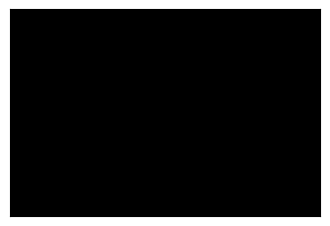

In [10]:
bandera = np.zeros((60, 90, 3), dtype=np.uint8)
print(bandera.shape)
print(bandera.dtype)
print(bandera[0, 0])
mostrar(bandera)

~~~text
(60, 90, 3)
uint8
[0 0 0]
~~~

*(Al ejecutar aparece la figura: un rectángulo negro.)*

El `.shape` tiene ahora **tres** números: `(60, 90, 3)` son 60 filas (alto), 90 columnas (ancho) y 3 canales (R, G, B). Es un arreglo **3D**: con dos índices, `bandera[0, 0]`, obtienes un píxel completo, y un píxel son tres números. `[0 0 0]` es negro: nada de rojo, nada de verde, nada de azul.

Estos son algunos colores como tripletas `[R, G, B]`, junto a su código hexadecimal (el que usan las páginas web y los programas de dibujo):

| Color | Tripleta `[R, G, B]` | Código hex |
|---|---|---|
| negro | `[0, 0, 0]` | `#000000` |
| blanco | `[255, 255, 255]` | `#FFFFFF` |
| rojo | `[255, 0, 0]` | `#FF0000` |
| verde | `[0, 255, 0]` | `#00FF00` |
| verde oscuro | `[0, 128, 0]` | `#008000` |
| azul | `[0, 0, 255]` | `#0000FF` |
| amarillo | `[255, 255, 0]` | `#FFFF00` |
| gris | `[200, 200, 200]` | `#C8C8C8` |

Cada par de dígitos hex es un canal: `FF` = 255, `80` = 128 y `C8` = 200. Dos dígitos hex son 8 bits, es decir, un byte (L02): justo lo que cabe en cada canal.

## Paso 6: pintar con rebanadas

Hasta ahora usaste las rebanadas para **leer** parte de un arreglo. También sirven para **escribir**: `arreglo[rebanada] = valor` cambia de una vez todos los elementos de esa rebanada. Si el valor es una tripleta `[R, G, B]`, NumPy la copia en **cada** píxel del rectángulo. (Parece romper la regla del Paso 4, pero no: la tripleta tiene justo 3 números, como el último eje, el de los canales, y NumPy la repite en cada píxel.) Pintemos una bandera de tres franjas horizontales de 20 filas cada una:

[255   0   0] [255 255 255] [  0   0 255]


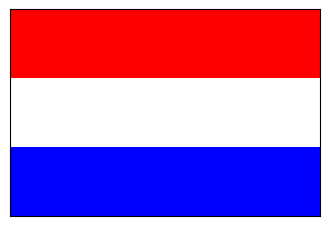

In [11]:
bandera[:20] = [255, 0, 0]          # filas 0-19: rojo
bandera[20:40] = [255, 255, 255]    # filas 20-39: blanco
bandera[40:] = [0, 0, 255]          # filas 40-59: azul

print(bandera[0, 0], bandera[30, 45], bandera[59, 89])
mostrar(bandera)

~~~text
[255   0   0] [255 255 255] [  0   0 255]
~~~

*(Al ejecutar aparece la figura: tres franjas horizontales, roja arriba, blanca en el medio y azul abajo.)*

Tres líneas y ningún `for`: `bandera[:20]` son las filas 0 a 19 con **todas** sus columnas. Para una franja **vertical** se rebanan las columnas: `bandera[:, :30]` son todas las filas, columnas 0 a 29.

Un tercer índice elige el **canal**: `imagen[:, :, 0]` es la capa roja (un arreglo 2D con la intensidad de rojo de cada píxel), `imagen[:, :, 1]` la verde e `imagen[:, :, 2]` la azul. Probemos en un lienzo nuevo: pintamos una franja vertical de gris (un solo número, `200`, va a los tres canales) y después apagamos sus canales rojo y verde.

[200 200 200]


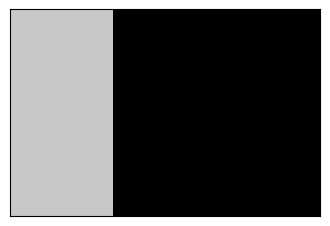

In [12]:
lienzo = np.zeros((60, 90, 3), dtype=np.uint8)
lienzo[:, :30] = 200        # columnas 0-29: gris (200 en los tres canales)
print(lienzo[0, 0])
mostrar(lienzo)

~~~text
[200 200 200]
~~~

*(Al ejecutar aparece la figura: una franja gris vertical a la izquierda, sobre fondo negro.)*

[  0   0 200]
(60, 90)


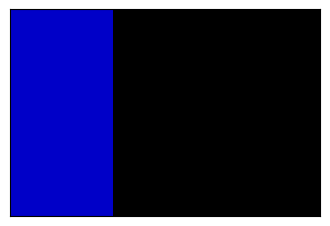

In [13]:
lienzo[:, :30, 0] = 0       # apaga el canal rojo de la franja
lienzo[:, :30, 1] = 0       # apaga el canal verde de la franja
print(lienzo[0, 0])
print(lienzo[:, :, 2].shape)
mostrar(lienzo)

~~~text
[  0   0 200]
(60, 90)
~~~

*(Al ejecutar aparece la figura: la misma franja, ahora azul.)*

Solo quedó encendido el canal azul (`200`), así que la franja se ve azul. Y `lienzo[:, :, 2]`, la capa azul sola, es un arreglo 2D de forma `(60, 90)`: una intensidad por píxel.

**Predice:** la franja blanca de la bandera es `[255, 255, 255]`. Si le apagas **solo** el canal azul, ¿de qué color queda? Piénsalo y luego ejecuta la celda. (Trabajamos sobre una **copia**: `bandera.copy()` crea un arreglo nuevo con los mismos números, así la bandera original no cambia.)

[255 255   0]


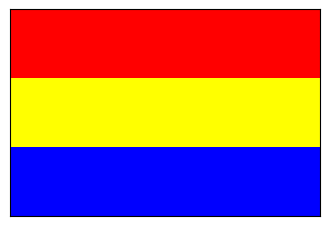

In [14]:
prueba = bandera.copy()
prueba[20:40, :, 2] = 0     # franja blanca: apaga el canal azul
print(prueba[30, 45])
mostrar(prueba)

<details><summary>Respuesta esperada</summary>

~~~text
[255 255   0]
~~~

*(Al ejecutar aparece la figura: la franja del medio ahora es amarilla.)*

Queda **amarilla**: `[255, 255, 0]` es rojo y verde al máximo, sin azul. En la luz de una pantalla los colores se **suman**, y rojo + verde = amarillo (revisa la tabla del Paso 5).
</details>

## Paso 7: máscaras sobre una imagen

Primero, la máscara en una dimensión. Una comparación sobre un arreglo da un arreglo de `True`/`False`, y usarlo como índice deja solo los elementos `True`:

In [15]:
print(temperaturas > 19)
print(temperaturas[temperaturas > 19])

[False  True False  True False  True]
[21. 22. 20.]


~~~text
[False  True False  True False  True]
[21. 22. 20.]
~~~

Lo mismo funciona en una imagen: una comparación sobre una capa da una **máscara** 2D de `True`/`False`, una por píxel. Busquemos los píxeles rojos. Un primer intento: "rojos son los que tienen el canal rojo al máximo".

In [16]:
es_rojo = bandera[:, :, 0] == 255
print(es_rojo.shape)
print(np.sum(es_rojo))

(60, 90)
3600


~~~text
(60, 90)
3600
~~~

¿Esperabas 1800? La franja roja tiene 20 filas x 90 columnas = 1800 píxeles, pero la máscara encontró el doble. El blanco `[255, 255, 255]` **también** tiene el canal rojo en 255, así que la máscara atrapó la franja roja y la blanca. Un color son **tres** números: para reconocerlo hay que mirar más de un canal. El operador `&` combina dos máscaras píxel a píxel ("y": las dos condiciones a la vez); cada comparación va entre paréntesis. Con arreglos se usa `&`, no el `and` de la L06: con `and` Python da un `ValueError`, y sin los paréntesis también falla.

In [17]:
es_rojo = (bandera[:, :, 0] == 255) & (bandera[:, :, 1] == 0)
print(np.sum(es_rojo))
print(round(np.sum(es_rojo) / (60 * 90), 2))

1800
0.33


~~~text
1800
0.33
~~~

Ahora sí: 1800 píxeles, un tercio (`0.33`) de los 60 x 90 = 5400 píxeles de la bandera. Con la máscara como índice cambias de color **todos** esos píxeles a la vez, sin `for`, igual que `temperaturas[temperaturas > 19]` elegía mediciones:

[  0 128   0] [255 255 255]


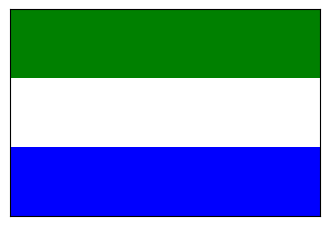

In [18]:
nueva = bandera.copy()
nueva[es_rojo] = [0, 128, 0]    # los pixeles rojos pasan a verde oscuro
print(nueva[0, 0], nueva[30, 0])
mostrar(nueva)

~~~text
[  0 128   0] [255 255 255]
~~~

*(Al ejecutar aparece la figura: la franja de arriba ahora es verde oscuro; la blanca y la azul no cambiaron.)*

### Cuidado con el límite de 255

**Predice:** quieres **aclarar** la bandera y le sumas 100 a todos sus números con `bandera + 100`. ¿Qué crees que pasará con el rojo `[255, 0, 0]` y con el blanco `[255, 255, 255]`?

[ 99 100 100] [99 99 99] [100 100  99]


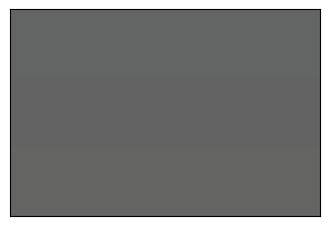

In [19]:
clara = bandera + 100
print(clara[0, 0], clara[30, 0], clara[59, 0])
mostrar(clara)

<details><summary>Respuesta esperada</summary>

~~~text
[ 99 100 100] [99 99 99] [100 100  99]
~~~

*(Al ejecutar aparece la figura: en vez de aclararse, la bandera queda en grises oscuros, con las tres franjas casi iguales.)*

¡Se oscureció! El rojo pasó a `[99 100 100]` y el blanco a `[99 99 99]`, un gris oscuro.
</details>

¿Por qué? Un `uint8` solo guarda de 0 a 255 (un byte). `255 + 100 = 355` no cabe, y NumPy no avisa: el número **da la vuelta** y empieza otra vez desde 0, así que queda `355 - 256 = 99`. Lo mismo le pasa a cada canal que estaba en 255. En cambio, `0 + 100 = 100` sí cabe.

La solución es **recortar** (*clipping*): hacer la suma con enteros comunes, que no tienen ese límite, y luego bajar a 255 todo lo que se pase. `.astype(int)` convierte el arreglo a enteros comunes; `np.clip(a, 0, 255)` deja cada número dentro del rango 0-255 (lo menor que 0 sube a 0 y lo mayor que 255 baja a 255); y `.astype(np.uint8)` lo devuelve al tipo de una imagen:

[255 100 100] [255 255 255] [100 100 255]


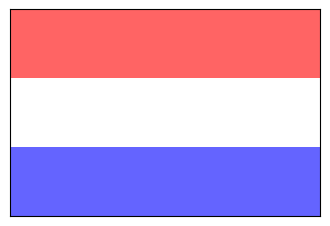

In [20]:
clara = np.clip(bandera.astype(int) + 100, 0, 255).astype(np.uint8)
print(clara[0, 0], clara[30, 0], clara[59, 0])
mostrar(clara)

~~~text
[255 100 100] [255 255 255] [100 100 255]
~~~

*(Al ejecutar aparece la figura: ahora sí, colores más claros: rosado arriba, blanco en el medio y azul claro abajo.)*

El rojo quedó `[255 100 100]` (rosado: el canal que ya estaba al máximo se queda en 255 y los otros suben), el blanco sigue blanco y el azul se aclaró a `[100 100 255]`.

## Tu turno (programa completo)

### Ejercicio 1: conteos celulares con un arreglo

Un microscopio contó las células de cinco muestras: `120, 135, 98, 142, 110`. Pon esos conteos en un arreglo de NumPy, calcula su **media** (con `round` a 2 decimales) y usa una **máscara booleana** para quedarte con los conteos **mayores que 120**. Completa la parte que falta.

In [21]:
# TODO: quita los # y completa la parte que falta (el operador de comparacion, ____).
# conteos = np.array([120, 135, 98, 142, 110])
#
# print(round(np.mean(conteos), 2))
# print(conteos[conteos ____ 120])

<details><summary>Respuesta esperada</summary>

~~~text
121.0
[135 142]
~~~

La parte que falta es `>` (mayor que): `conteos[conteos > 120]`. La media es `round(np.mean(conteos), 2)` -> `(120 + 135 + 98 + 142 + 110) / 5 = 121.0`. La máscara `conteos > 120` marca cada conteo como `True`/`False`, y `conteos[conteos > 120]` devuelve solo los que pasan: `[135 142]` (los conteos `120`, `98` y `110` no son mayores que `120`). Es el filtro de la L19, ahora sin un `for`.
</details>

### Ejercicio 2: una bandera con cruz

Una bandera de fondo azul con una cruz amarilla: una franja horizontal (filas 25 a 34) y una franja vertical (columnas 30 a 39). La franja horizontal ya está pintada; completa la rebanada de **columnas** de la vertical. Al final, una máscara cuenta los píxeles amarillos (en esta bandera, el amarillo es el único color sin azul).

In [22]:
# TODO: quita los # y completa la rebanada de columnas (____) de la franja vertical.
# cruz = np.zeros((60, 90, 3), dtype=np.uint8)
# cruz[:, :] = [0, 0, 255]          # fondo azul
# cruz[25:35, :] = [255, 255, 0]    # franja horizontal amarilla
# cruz[:, ____] = [255, 255, 0]     # franja vertical amarilla
#
# print(cruz[0, 0], cruz[5, 35])
# print(np.sum(cruz[:, :, 2] == 0))
# mostrar(cruz)

<details><summary>Respuesta esperada</summary>

~~~text
[  0   0 255] [255 255   0]
1400
~~~

La parte que falta es `30:40` (columnas 30 a 39; el final de una rebanada no se incluye). `cruz[0, 0]` es fondo azul y `cruz[5, 35]` cae en la franja vertical: amarillo. Los píxeles amarillos son `1400`: la franja horizontal tiene 10 x 90 = 900, la vertical 60 x 10 = 600, y los 10 x 10 = 100 del cruce se contarían dos veces, así que 900 + 600 - 100 = 1400. La figura muestra una cruz amarilla sobre fondo azul, con el brazo vertical más cerca del lado izquierdo.
</details>

### Ejercicio 3 (opcional): desafío -- una bandera de tres franjas verticales

Escribe tú todo el programa. En un lienzo de forma `(60, 90, 3)`, pinta tres franjas **verticales** de 30 columnas cada una: verde oscuro `[0, 128, 0]` a la izquierda, blanco en el centro y rojo a la derecha. Imprime un píxel del centro de cada franja (fila 30; columnas 15, 45 y 75) y muestra la bandera. Extra: con una máscara, cuenta los píxeles **blancos** (cuidado: el blanco no es el único color con el canal rojo al máximo).

In [23]:
# Escribe aqui tu programa (desafio opcional).

<details><summary>Respuesta esperada</summary>

Una solución:

~~~python
tricolor = np.zeros((60, 90, 3), dtype=np.uint8)
tricolor[:, :30] = [0, 128, 0]        # columnas 0-29: verde oscuro
tricolor[:, 30:60] = [255, 255, 255]  # columnas 30-59: blanco
tricolor[:, 60:] = [255, 0, 0]        # columnas 60-89: rojo

print(tricolor[30, 15], tricolor[30, 45], tricolor[30, 75])
es_blanco = (tricolor[:, :, 0] == 255) & (tricolor[:, :, 1] == 255)
print(np.sum(es_blanco))
mostrar(tricolor)
~~~

~~~text
[  0 128   0] [255 255 255] [255   0   0]
1800
~~~

Las franjas verticales se pintan rebanando **columnas** (`[:, inicio:fin]`). Para los blancos, `tricolor[:, :, 0] == 255` también atraparía el rojo (3600 píxeles); pedir además el verde al máximo deja solo el blanco: 60 x 30 = 1800.
</details>

## Resumen

- Se **importa** con `import numpy as np`; a partir de ahí todo es `np.algo`.
- `np.array([...])` crea un **arreglo** de números del mismo tipo, optimizado para cálculo.
- Las operaciones son **vectorizadas**: `arreglo + 2`, `arreglo * 1.8 + 32` actúan sobre **todos** los elementos a la vez, sin un `for`. (`lista * 2` repite; `arreglo * 2` duplica cada elemento.)
- Los **agregados** son una llamada: `np.mean`, `np.std` (muéstrala con `round`), `np.sum`, `np.max`, `np.min`.
- Un arreglo se indexa/rebana como una lista; una **matriz** 2D tiene `.shape`, `M[i, j]` y `M[:, j]` (una columna).
- Una **máscara booleana** `a[a > umbral]` filtra sin `for`, y `np.sum(a > umbral)` cuenta los que cumplen.
- Una **imagen a color** es un arreglo **3D** `(alto, ancho, 3)` de `uint8`: cada píxel es una tripleta `[R, G, B]` de 0 a 255 (en hex, dos dígitos por canal).
- Las rebanadas también **escriben**: `img[:20] = [255, 0, 0]` pinta una franja de una vez; `img[:, :, k]` es la capa 2D del canal `k`.
- Una máscara sobre la imagen elige píxeles: `&` combina condiciones (un color son tres números), `img[mascara] = color` los recolorea y `np.sum(mascara)` los cuenta.
- Un `uint8` **da la vuelta** al pasar de 255 (`255 + 100` -> `99`); para aclarar sin ese problema, recorta: `np.clip(img.astype(int) + 100, 0, 255).astype(np.uint8)`.
- **Sigue en la L21** con **Pandas**: una columna de un `DataFrame` es, por dentro, un arreglo de NumPy, así que `df['col'].mean()` usa el `mean` de hoy. En la L24 volverás a las imágenes, ahora de microscopio.